# Wang et al. 2019 — Glioblastoma (10x) · 04 EMT-TF Expression
Unconditional final step (produced regardless of gate outcome). Score a broad EMT-TF panel (Snail/Zeb/Twist **plus**
FOXC and PRRX families; VIM excluded — it is a mesenchymal marker, not a TF), gated on detectable expression, and
overlay the two most-expressed factors as a categorical overlay of thresholded expressers on the grey **native**
manifold (reference style). Note Gate 2 was NO-GO, so no developmental ordering is asserted here.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| native embedding')
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = [(g, round((X[:,j]>0).mean(),3), round(X[:,j][X[:,j]>0].mean() if (X[:,j]>0).any() else 0,3)) for j,g in enumerate(present)]
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_in_expr']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
top2 = ok.TF.tolist()[:2]
print('detectable TFs (frac>0.03):', ok.TF.tolist(), '| shown:', top2)

cells: 9634 | native embedding
    TF  frac_expr  mean_in_expr
  ZEB1      0.699         1.582
  ZEB2      0.670         1.395
 PRRX1      0.398         1.080
TWIST1      0.043         0.721
 SNAI2      0.016         0.443
 SNAI1      0.006         0.548
 FOXC1      0.006         0.540
 PRRX2      0.005         0.659
TWIST2      0.003         0.982
 FOXC2      0.001         0.736
detectable TFs (frac>0.03): ['ZEB1', 'ZEB2', 'PRRX1', 'TWIST1'] | shown: ['ZEB1', 'ZEB2']


### Figure — expression.pdf (categorical overlay on grey native manifold)

ZEB1: 69.9% expressing; 1683 shown (upper quartile among expressers)
ZEB2: 67.0% expressing; 1614 shown (upper quartile among expressers)
saved expression.pdf


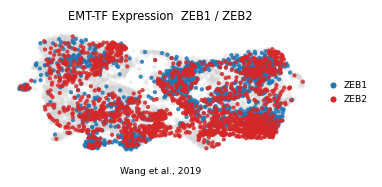

In [4]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in top2:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in top2}
order = sorted(top2, key=lambda g: -int(sel[g].sum()))
colors = {top2[0]:'tab:blue', top2[1]:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0],[0], marker='o', color='w', markerfacecolor=colors[top2[0]], markersize=5, label=top2[0]),
                   Line2D([0],[0], marker='o', color='w', markerfacecolor=colors[top2[1]], markersize=5, label=top2[1])],
          frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=6, handletextpad=.2)
ax.set_title(f'EMT-TF Expression  {top2[0]} / {top2[1]}', size=7.5)
ax.text(.5, -.14, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in top2:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (upper quartile among expressers)')
print('saved expression.pdf')